In [24]:
import torch
import torch.nn as nn
import torch.optim as optim
#from tqdm.notebook import trange, tqdm
from tqdm.auto import trange, tqdm
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import time
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
import scipy.io as sio
import pandas as pd
import joblib

# for inference
from scipy import stats
from scipy.stats import gaussian_kde
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error





Dataset

In [25]:
# Carica il file di testo (rileva automaticamente i nomi delle colonne dalla prima riga)
# 1. Load dataset
column_names = ['B_magn_T', 'TPU_L_mm', 't_index', 't_val_s', 'x_coord_m', 'H_val_Am', 'B_val_T']

df = pd.read_csv('Dataset_BH_distribution.txt', sep=r'\s+', header=None, names=column_names, index_col=False)

# dataset shape
print("Shape del dataset originale:", df.shape)

# remove data with B = 0
df_no_zero = df[df['B_magn_T'] != 0]
print("Shape del dataset senza zeri:", df_no_zero.shape)

# only time instant 1
df_no_zero_t_1 = df_no_zero[df_no_zero['t_index'] == 1]
print("Shape del dataset filtrato - time instant 1:", df_no_zero_t_1.shape)
# print(df_no_zero_t_1.iloc[0:100])



Shape del dataset originale: (872641, 7)
Shape del dataset senza zeri: (872641, 7)
Shape del dataset filtrato - time instant 1: (7325, 7)


C:\Users\andre\AppData\Local\Temp\ipykernel_55292\2100672312.py:5: DtypeWarning: Columns (0: B_magn_T, 1: TPU_L_mm, 2: t_index, 3: t_val_s, 4: x_coord_m, 5: H_val_Am, 6: B_val_T) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('Dataset_BH_distribution.txt', sep=r'\s+', header=None, names=column_names, index_col=False)


NN settings

In [26]:
### -----------------------------------------------------------------------------------------------

# INPUT:  TPU_L_mm, x_coord_m, B_val_T
x = df_no_zero_t_1[['TPU_L_mm','x_coord_m', 'B_val_T']].values
# OUTPUT: H_val_Am
y = df_no_zero_t_1['H_val_Am'].values

### -----------------------------------------------------------------------------------------------

# print shapes
print('Input and output shape:', x.shape, y.shape)

# check what's inside if u are interested
# print(y)

# SPLIT THE DATASET INTO TRAIN, VAL AND TEST SETS 
X_train, X_test_1stcut, y_train, y_test_1stcut = train_test_split(x, y, test_size=0.3, random_state=42)
X_test, X_val, y_test, y_val = train_test_split(X_test_1stcut, y_test_1stcut, test_size=0.5, random_state=42)

# SCALE THE DATASET
# Initialize the [0,1] scaler
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

# aplly the scaling (x-xmin)/(xmax-xmin) to TRAIN
X_train_scaled = scaler_X.fit_transform(X_train)
Y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1))

# apply the same transformation to VAL
X_val_scaled = scaler_X.transform(X_val)
Y_val_scaled = scaler_y.transform(y_val.reshape(-1, 1))

# apply the same transformation to TEST
X_test_scaled = scaler_X.transform(X_test)
Y_test_scaled = scaler_y.transform(y_test.reshape(-1, 1))

# shape check
print('Training set shape:', X_train_scaled.shape, Y_train_scaled.shape)
print('Validation set shape:', X_val_scaled.shape, Y_val_scaled.shape)
print('Test set shape:', X_test_scaled.shape, Y_test_scaled.shape)

#check scaling
print(Y_train_scaled[0:5])


Input and output shape: (7325, 3) (7325,)
Training set shape: (5127, 3) (5127, 1)
Validation set shape: (1099, 3) (1099, 1)
Test set shape: (1099, 3) (1099, 1)
[[0.08587402]
 [0.18796659]
 [0.00701274]
 [0.12231053]
 [0.99819553]]


NN Initialization

In [27]:
# initialize the NN
class NN_get_BofX(nn.Module):
    def __init__(self, n_input, n_output, n_hidden1=16,n_hidden2=16): #relu 16
        super(NN_get_BofX, self).__init__()
        self.fc1 = nn.Linear(n_input, n_hidden1)  # 3 input features,
        self.fc2 = nn.Linear(n_hidden1, n_hidden2) #
        self.fc3 = nn.Linear(n_hidden2, n_output)  # 1 output
        self.ReLU  = nn.ReLU ()
    def forward(self, x):
        x = self.ReLU (self.fc1(x))
        x = self.ReLU (self.fc2(x))
        x = self.fc3(x)
        return x

In [28]:
# convert SCALED data to torch tensors

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)


y_train_tensor = torch.tensor(Y_train_scaled, dtype=torch.float32).view(-1, 1)
y_test_tensor = torch.tensor(Y_test_scaled, dtype=torch.float32).view(-1, 1)
y_val_tensor = torch.tensor(Y_val_scaled, dtype=torch.float32).view(-1, 1)


# shape check
print('Training set shape:', X_train_tensor.shape, y_train_tensor.shape)
print('Test set shape:', X_test_tensor.shape, y_test_tensor.shape)
print('Validation set shape:', X_val_tensor.shape, y_val_tensor.shape)
#check tensors
print(y_train_tensor[0:2])

Training set shape: torch.Size([5127, 3]) torch.Size([5127, 1])
Test set shape: torch.Size([1099, 3]) torch.Size([1099, 1])
Validation set shape: torch.Size([1099, 3]) torch.Size([1099, 1])
tensor([[0.0859],
        [0.1880]])


In [29]:
# group everything for BATCH TRAINING
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)


train_data = DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)
val_data   = DataLoader(dataset=val_dataset,   batch_size=64, shuffle=False)
test_data  = DataLoader(dataset=test_dataset,  batch_size=64, shuffle=False)

In [30]:
# Initialize all u need for the NN trainign loop

n_input = X_train_tensor.shape[1]
n_output = y_train_tensor.shape[1]
model = NN_get_BofX(n_input,n_output)
loss_criterion = nn.MSELoss()
eta = 1e-3 # Learning Rate
optimizer = optim.Adam(model.parameters(), lr=eta)
n_epochs = 150

Training and validation and testing function

In [31]:
#training loop
def train_model(model, train_data, loss_criterion, optimizer, loss_logger, epoch_idx):
  total_loss = 0
  for batch_idx, (data,target) in enumerate(tqdm(train_data, desc="Training", leave=False)):
    pred_output = model(data)
    loss = loss_criterion(pred_output, target)
    optimizer.zero_grad() # Clears all gradients; prevent gradient accumulation
    loss.backward() # Computes gradient of loss wrt model parameters
    optimizer.step() # Updates model paraments using computed gradients
    #loss_logger.append(loss.item()) # Logs the loss; convenient if batch_size = dataset_size
    # .item() - Converts tensor into a python number
    total_loss += loss.item() # Track/accumulate the loss

  avg_loss = total_loss / len(train_data) # Compute the average loss
  loss_logger.append(avg_loss) # Store the loss

  #print(f"Epoch: {epoch_idx} | Loss: {avg_loss:.4f}")


  return model, optimizer, loss_logger

#validation

def validate_model(model, val_data, loss_criterion, val_loss_logger):
    model.eval() # Set to evaluation mode
    total_loss = 0
    with torch.no_grad():
        for data, target in val_data:
            pred_output = model(data)
            loss = loss_criterion(pred_output, target)
            total_loss += loss.item()

    avg_loss = total_loss / len(val_data)
    val_loss_logger.append(avg_loss)
    return val_loss_logger

# tetsting

def test_model(model, test_data, loss_criterion, loss_logger):
  total_loss = 0
  with torch.no_grad():
    for batch_idx, (data,target) in enumerate(tqdm(test_data, desc="Testing", leave=False)):
      pred_output = model(data)
      loss = loss_criterion(pred_output, target)
      #loss_logger.append(loss.item())
      total_loss += loss.item()

    avg_loss = total_loss / len(test_data)
    loss_logger.append(avg_loss)

    return loss_logger

Training LOOP

In [32]:
train_loss = []
val_loss = []
test_loss = []

for i in trange(n_epochs, desc="Epoch", leave=False):
    # Train
    model, optimizer, train_loss = train_model(model, train_data, loss_criterion, optimizer, train_loss, epoch_idx=i)

    # Validate (Check performance on unseen "practice" data)
    val_loss = validate_model(model, val_data, loss_criterion, val_loss)

    # Optional: Print progress
    # print(f"Epoch {i}: Train Loss: {train_loss[-1]:.4f} | Val Loss: {val_loss[-1]:.4f}")


# 3. Test (Only once, after all epochs are finished)
test_loss = test_model(model, test_data, loss_criterion, test_loss)

In [33]:
# SALVATAGGIO

# Salva il modello PyTorch
torch.save(model.state_dict(), 'model_Bx_To_Hx.pth')

# Salva lo scaler
joblib.dump(scaler_X, 'scaler_X_Bx_to_Hx.pkl')
joblib.dump(scaler_y, 'scaler_y_Bx_to_Hx.pkl')

print("Modello e scaler salvati")

Modello e scaler salvati


Results assessment

In [34]:
# Assess final results (solution)

def assess_results(model, X, y, data_type):
    model.eval()
    with torch.no_grad():
        y_hat = model(X)

        # Prediction and plotting
        #plt.figure(figsize = (4, 4))
        #plt.plot(y_hat.numpy(), 'r-', label='Predicted output')
        #plt.plot(y.numpy(), 'b-', label='True output')
        #plt.title(f'Predicted vs Estimated output: {data_type} dataset')  # Fixed f-string
        #plt.legend()
        #plt.show()

        # Prediction and plotting
        plt.figure(figsize = (2, 2))
        plt.scatter(y_hat.numpy(), y.numpy())
        plt.xlabel('Predicted output')
        plt.ylabel('True output')
        plt.title(f'Predicted vs Estimated output: {data_type} dataset')  # Fixed f-string
        plt.legend()
        plt.grid(True)
        plt.show()

        # RMSE calculation
        mse = torch.mean((y_hat - y) ** 2)
        rmse = torch.sqrt(mse)


        # R2 calculation
        total_variance = torch.var(y)
        residual_variance = torch.mean((y_hat - y) ** 2)
        R2 = 1 - residual_variance / total_variance

    return rmse, R2

C:\Users\andre\AppData\Local\Temp\ipykernel_55292\1200807130.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


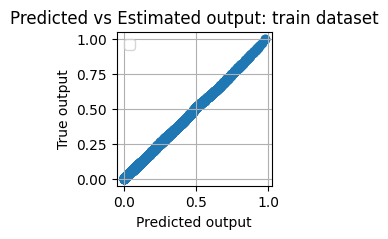

Training results
rmse = 0.0024. R2 = 1.000


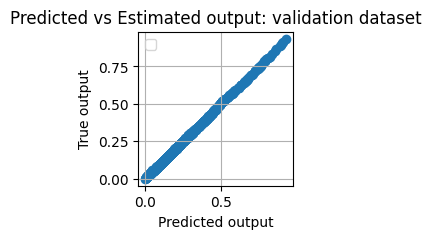

Validation results
rmse = 0.0025. R2 = 1.000


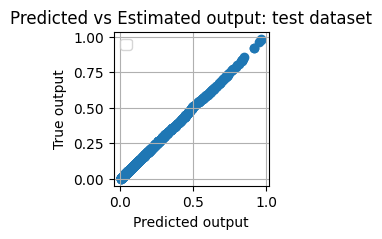

Test results
rmse = 0.0025. R2 = 1.000


In [35]:
# Assess results in training
rmse_train, R2_train = assess_results(model, X_train_tensor, y_train_tensor.view(-1,1), data_type = 'train')
print('Training results')
print(f"rmse = {rmse_train:.4f}. R2 = {R2_train:.3f}")

# Assess results in validation
rmse_val, R2_val = assess_results(model, X_val_tensor, y_val_tensor.view(-1,1), data_type = 'validation')
print('Validation results')
print(f"rmse = {rmse_val:.4f}. R2 = {R2_val:.3f}")

# Assess results in test
rmse_test, R2_test = assess_results(model, X_test_tensor, y_test_tensor.view(-1,1), data_type = 'test')
print('Test results')
print(f"rmse = {rmse_test:.4f}. R2 = {R2_test:.3f}")

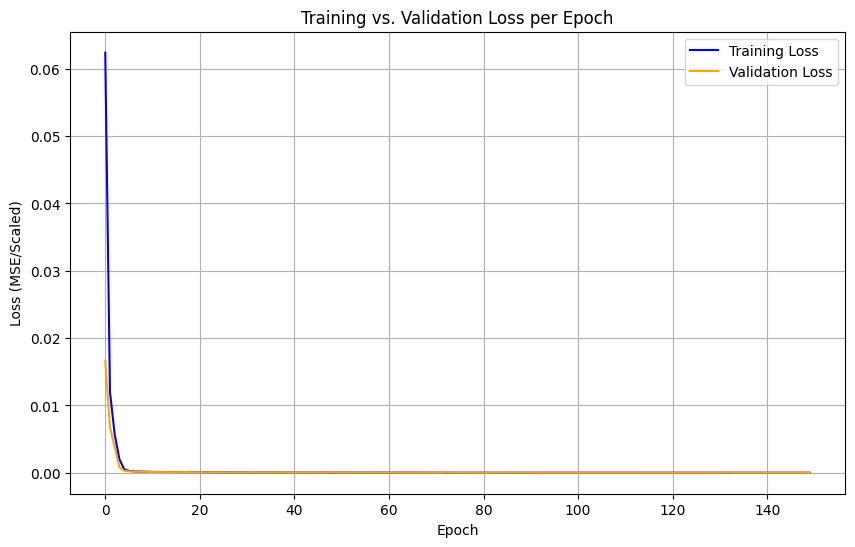

Final Training Loss: 0.000007
Final Validation Loss: 0.000006
Final Test Loss: 0.0000


In [36]:
plt.figure(figsize=(10, 6))

# Plotting both on the same axes
plt.plot(train_loss, label='Training Loss', color='blue')
plt.plot(val_loss, label='Validation Loss', color='orange')

# Training and Validation Plot
plt.title('Training vs. Validation Loss per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE/Scaled)')
plt.legend()
plt.grid(True)
plt.show()


print(f"Final Training Loss: {train_loss[-1]:.6f}")
print(f"Final Validation Loss: {val_loss[-1]:.6f}")
print(f"Final Test Loss: {test_loss[-1]:.4f}")

Parity plot for inference

In [37]:
# ═══════════════════════════════════════════════════════════════════
# CELLA 1 — Raccogli predizioni su tutto il test set (scala ORIGINALE)
# IMPORTANTE: y_test_tensor è SCALATA → bisogna riportare tutto a A/m
# Incolla DOPO l'ultimo assess_results / training loop
# ═══════════════════════════════════════════════════════════════════

model.eval()
with torch.no_grad():
    y_pred_scaled = model(X_test_tensor).numpy().ravel()   # spazio [0,1]

# Riporta alla scala originale [A/m]
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()
y_true = y_test   # già in A/m — variabile originale non scalata

# Features originali (non scalate) corrispondenti al test set
# X_test ha colonne: [TPU_L_mm, x_coord_m, B_val_T]
feat_TPU  = X_test[:, 0]
feat_x    = X_test[:, 1]
feat_Bval = X_test[:, 2]

residuals = y_pred - y_true
abs_err   = np.abs(residuals)
rel_err   = abs_err / (np.abs(y_true) + 1e-9)

r2   = r2_score(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mae  = mean_absolute_error(y_true, y_pred)

print(f"TEST SET — H(x):  R²={r2:.4f}  RMSE={rmse:.2f} A/m  MAE={mae:.2f} A/m")
print(f"Errore relativo:  mediana={np.median(rel_err):.3%}  "
      f"P90={np.percentile(rel_err,90):.3%}  P95={np.percentile(rel_err,95):.3%}")

TEST SET — H(x):  R²=0.9998  RMSE=640.33 A/m  MAE=392.93 A/m
Errore relativo:  mediana=0.751%  P90=2.549%  P95=4.321%


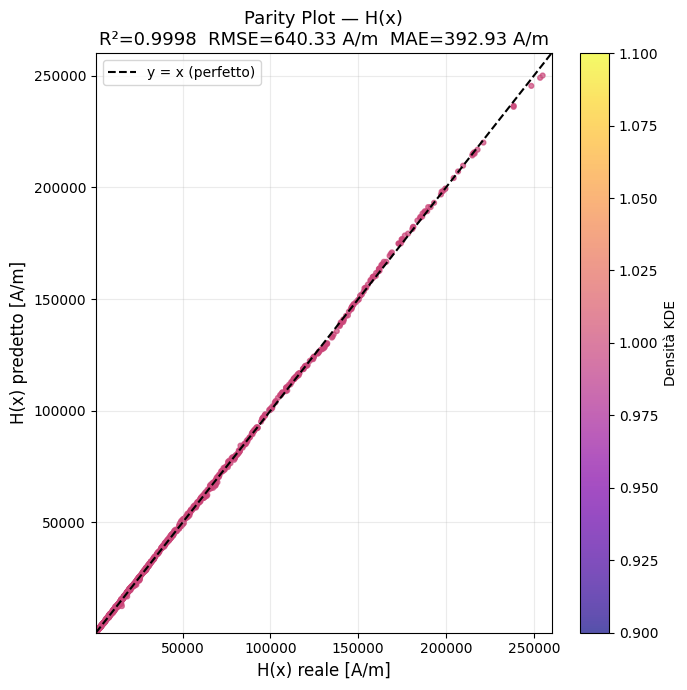

In [38]:
# ═══════════════════════════════════════════════════════════════════
# CELLA 2 — Parity plot classico con densità KDE
# ═══════════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(7, 7))

xy = np.vstack([y_true, y_pred])
try:
    z = gaussian_kde(xy)(xy)
except Exception:
    z = np.ones(len(y_true))
idx_sort = z.argsort()

sc = ax.scatter(y_true[idx_sort], y_pred[idx_sort],
                c=z[idx_sort], s=12, cmap='plasma', alpha=0.7, rasterized=True)
plt.colorbar(sc, ax=ax, label='Densità KDE')

lim = [min(y_true.min(), y_pred.min()) * 0.98,
       max(y_true.max(), y_pred.max()) * 1.02]
ax.plot(lim, lim, 'k--', lw=1.5, label='y = x (perfetto)')
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel('H(x) reale [A/m]', fontsize=12)
ax.set_ylabel('H(x) predetto [A/m]', fontsize=12)
ax.set_title(f'Parity Plot — H(x)\nR²={r2:.4f}  RMSE={rmse:.2f} A/m  MAE={mae:.2f} A/m', fontsize=13)
ax.legend(fontsize=10); ax.grid(True, alpha=0.25)
plt.tight_layout()
#plt.savefig('parity_H_classic.png', dpi=150, bbox_inches='tight')
plt.show()
#print("Salvato: parity_H_classic.png")

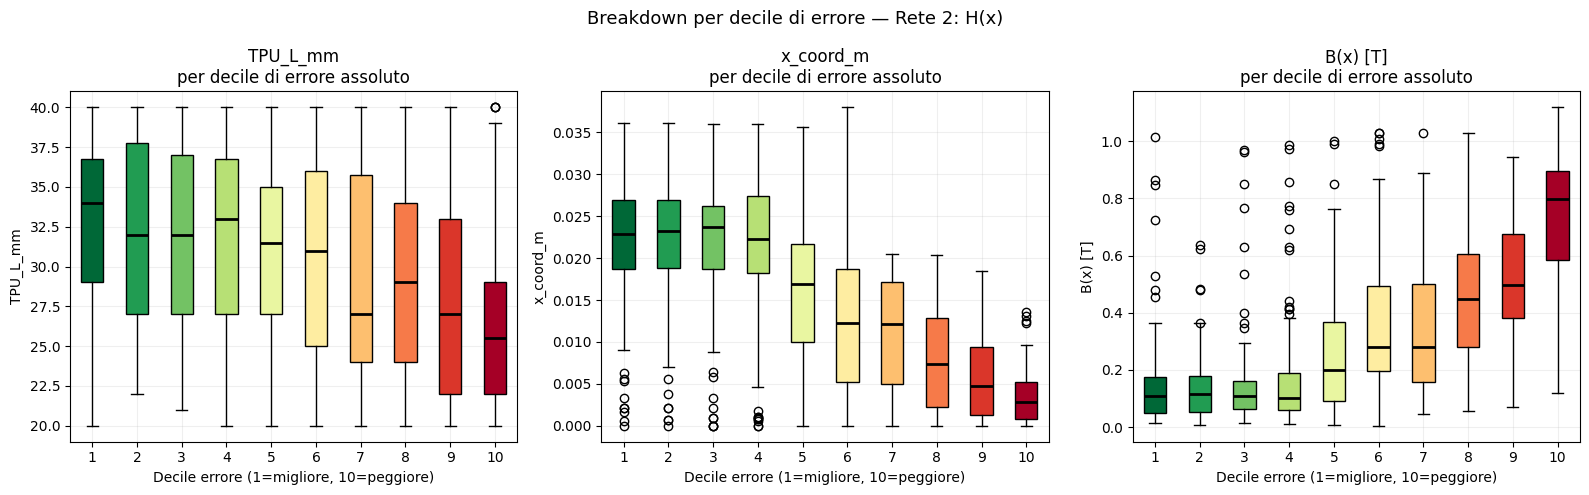

Salvato: parity_H_decile_breakdown.png


In [39]:

# ═══════════════════════════════════════════════════════════════════
# CELLA 5 — Percentile breakdown per feature
# ═══════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Breakdown per decile di errore — Rete 2: H(x)', fontsize=13)

bins_err = pd.qcut(abs_err, q=10, duplicates='drop', labels=False)
cmap_bp  = plt.cm.RdYlGn_r

for ax, feat_vals, lbl in zip(
    axes,
    [feat_TPU, feat_x, feat_Bval],
    ['TPU_L_mm', 'x_coord_m', 'B(x) [T]']
):
    data_by_dec = [feat_vals[bins_err == i] for i in range(10)]
    bp = ax.boxplot(data_by_dec, patch_artist=True,
                    medianprops=dict(color='black', lw=2))
    for patch, i in zip(bp['boxes'], range(10)):
        patch.set_facecolor(cmap_bp(i / 9))
    ax.set_xlabel('Decile errore (1=migliore, 10=peggiore)')
    ax.set_ylabel(lbl)
    ax.set_title(f'{lbl}\nper decile di errore assoluto')
    ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.savefig('parity_H_decile_breakdown.png', dpi=150, bbox_inches='tight')
plt.show()
print("Salvato: parity_H_decile_breakdown.png")




Subplot ventaglio curve

In [40]:
# ═══════════════════════════════════════════════════════════════════
# VENTAGLIO DI CURVE H(x) per ogni TPU_L
# Per ogni valore di TPU_L disponibile → un subplot
# Dentro ogni subplot: una curva per ogni B_magn disponibile
# ═══════════════════════════════════════════════════════════════════

# ── PARAMETRI ────────────────────────────────────────────────────
SHOW_TRUE   = True    # True = sovrappone anche la curva reale
SCALE_LOG   = False   # True = asse y in scala logaritmica
# ─────────────────────────────────────────────────────────────────

# Valori unici di TPU_L e B_magn nel dataset
tpu_vals  = sorted(df_no_zero_t_1['TPU_L_mm'].unique())
b_vals    = sorted(df_no_zero_t_1['B_magn_T'].unique())


n_tpu  = len(tpu_vals)
n_cols = 3
n_rows = int(np.ceil(n_tpu / n_cols))

print(f"Valori unici di TPU_L: {tpu_vals}")
print(f"Valori unici di B_magn: {b_vals}")
print(f"Organizzazione subplot: {n_rows} righe x {n_cols} colonne")

Valori unici di TPU_L: [20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40]
Valori unici di B_magn: [0.189473684210526, 0.252631578947368, 0.315789473684211, 0.378947368421053, 0.442105263157895, 0.505263157894737, 0.568421052631579, 0.631578947368421, 0.694736842105263, 0.757894736842105, 0.821052631578947, 0.88421052631579, 0.947368421052632, 1.01052631578947, 1.07368421052632, 1.13684210526316, 1.2]
Organizzazione subplot: 7 righe x 3 colonne


[[20 0.0 0.1864954293729]
 [20 0.0005331832613836 0.300492003897653]
 [20 0.0011800743371539 0.361466551874009]
 [20 0.0019649177904315 0.379983946903438]
 [20 0.0029171301142515 0.373844557976587]
 [20 0.0040724007451964 0.348430798114643]
 [20 0.0054025463273764 0.309965539767406]
 [20 0.0067666715969417 0.269065876622961]
 [20 0.0081333357984708 0.230604145836792]
 [20 0.0094999999999999 0.196648063194758]
 [20 0.0108666642015291 0.166683884991373]
 [20 0.0122333284030583 0.141056432420488]
 [20 0.0135974536726236 0.11852349751214]
 [20 0.0149275992548036 0.0990278141583285]
 [20 0.0160828698857484 0.083198080620242]
 [20 0.0170350822095684 0.069816750286528]
 [20 0.017819925662846 0.0570668838727592]
 [20 0.0184668167386161 0.042027758476791]
 [20 0.0189999999999989 0.022233047547483]]
[[20 0.0 0.228901879430276]
 [20 0.0005331832613836 0.372199350738478]
 [20 0.0011800743371539 0.44419264280905]
 [20 0.0019649177904315 0.46471140021607]
 [20 0.0029171301142515 0.45645312037855]
 [

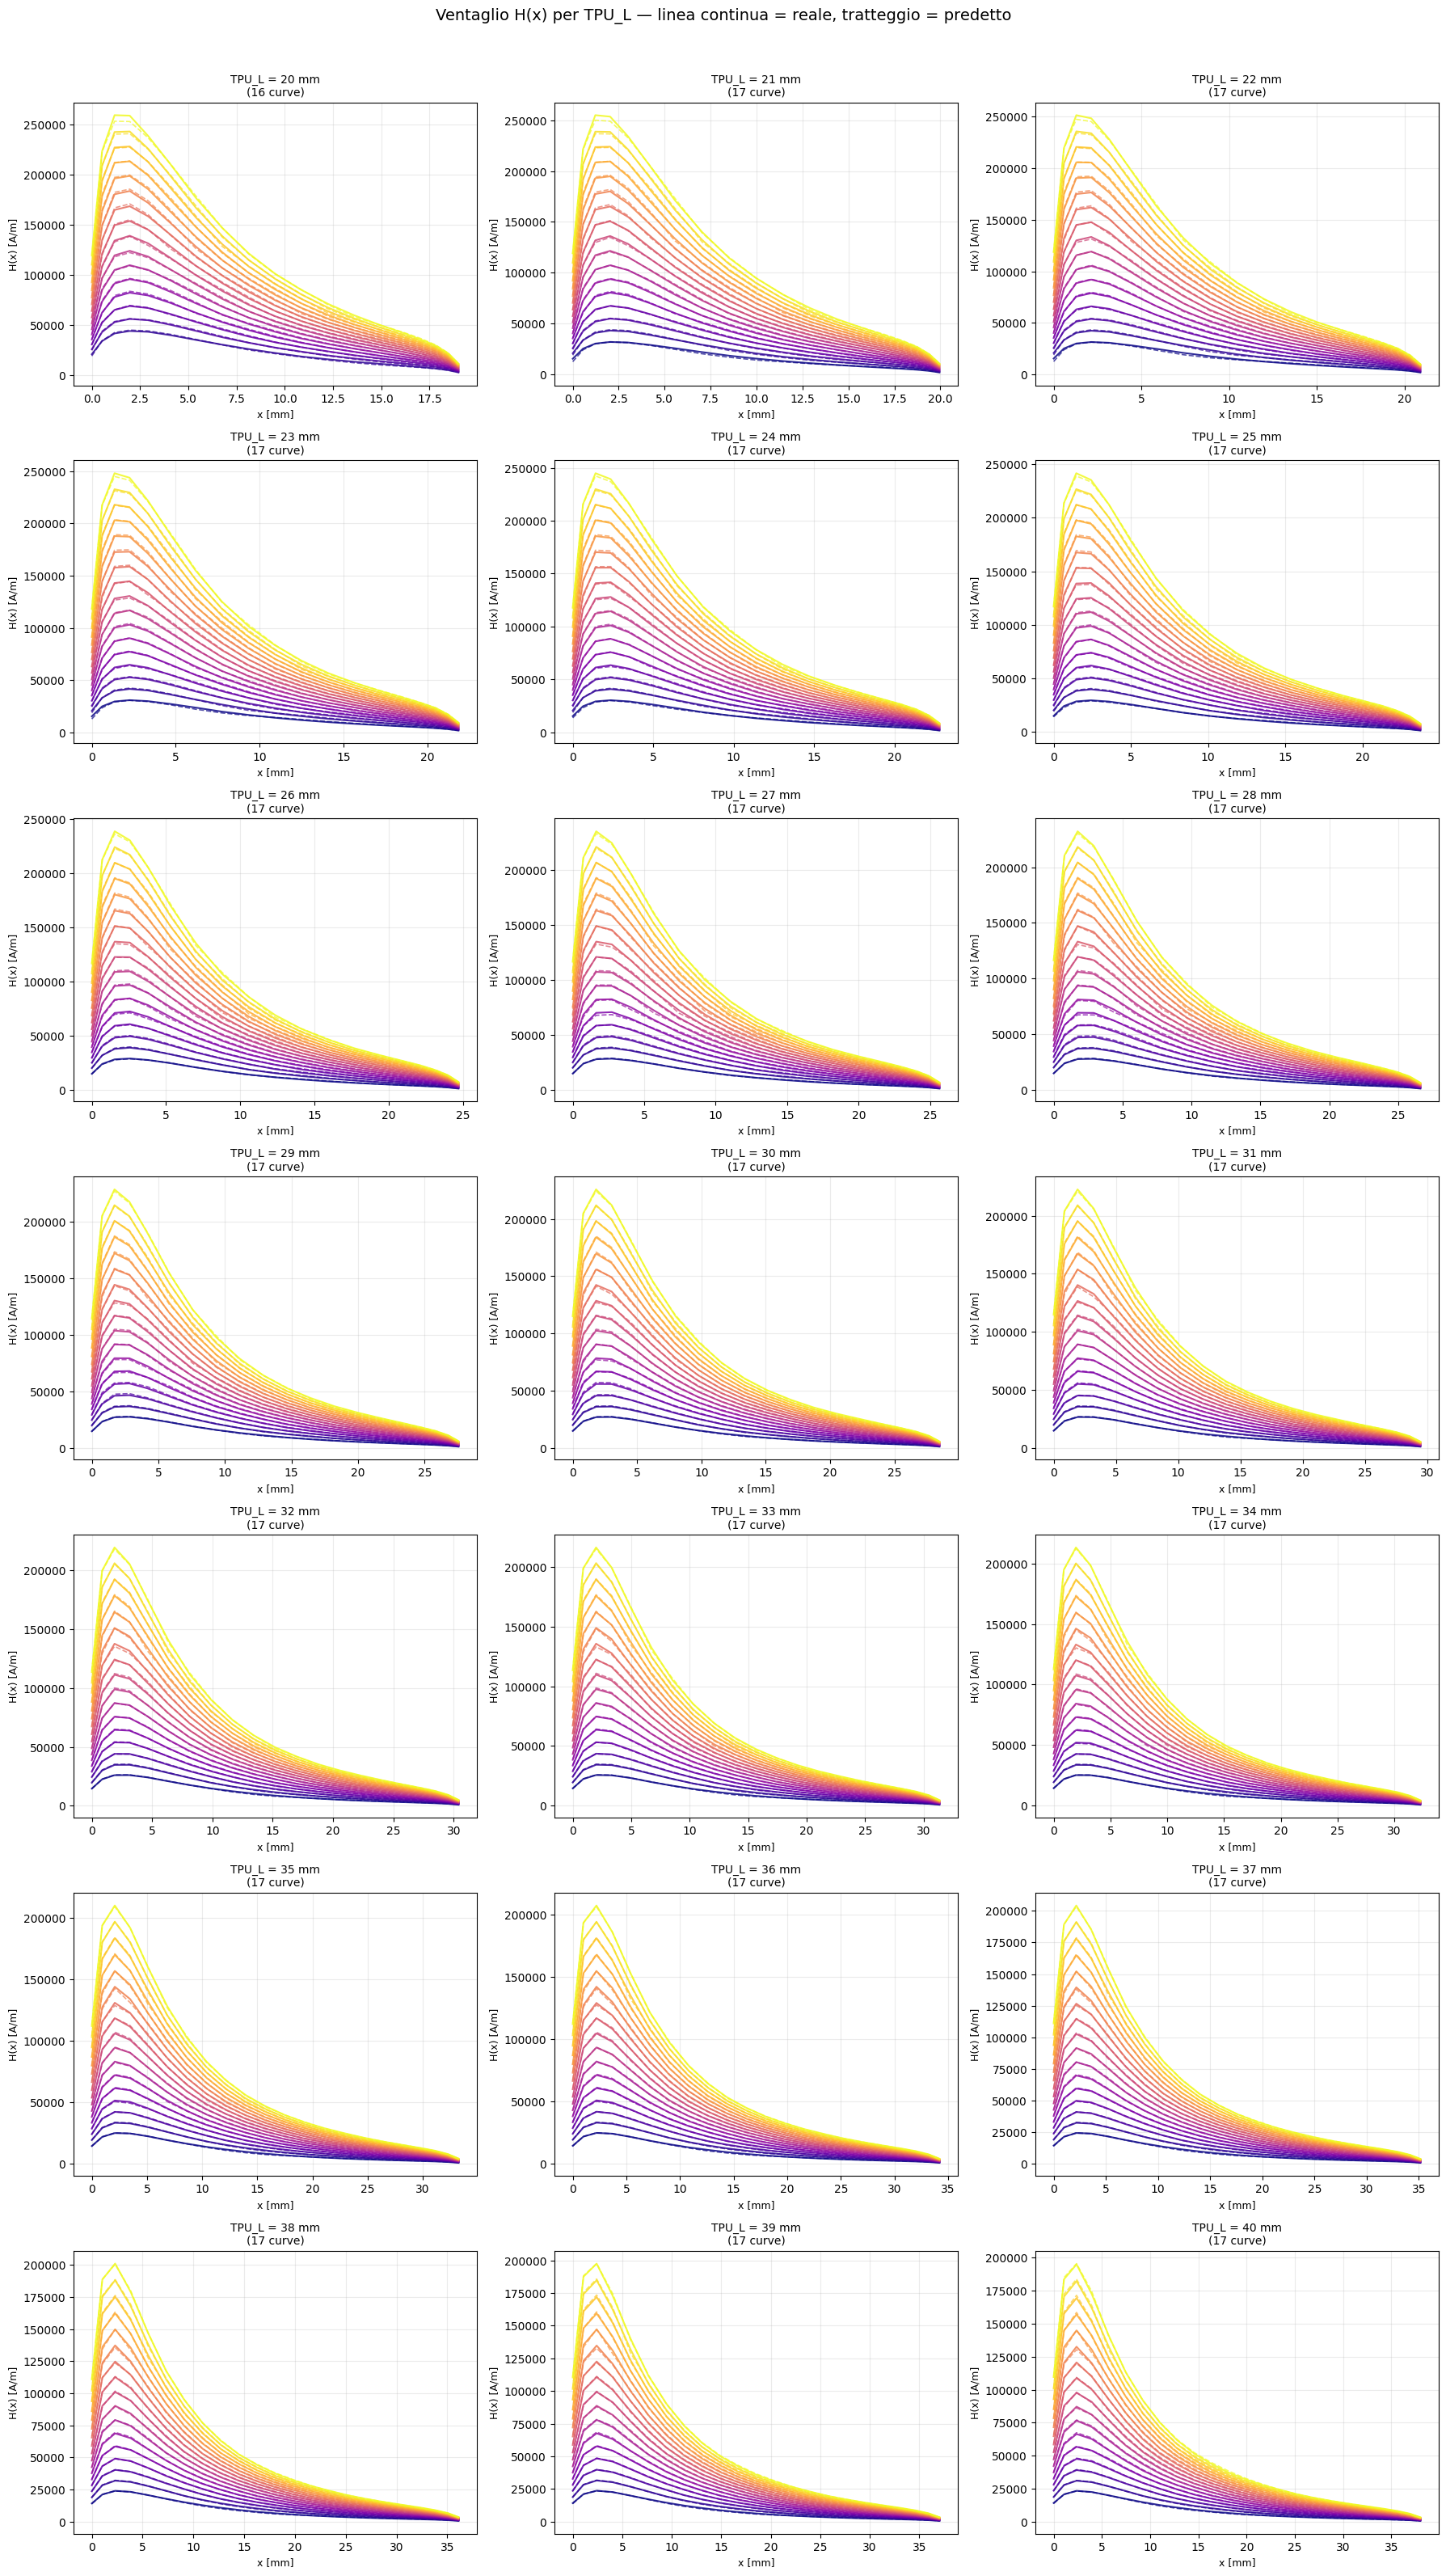

Plottati 21 subplot, 17 curve per subplot


In [41]:
# Colormap: una curva per B_magn
cmap   = plt.cm.plasma
norm   = plt.Normalize(vmin=min(b_vals), vmax=max(b_vals))

fig, axes = plt.subplots(n_rows, n_cols,
                          figsize=(6 * n_cols, 4.5 * n_rows),
                          sharey=False)
axes_flat = axes.ravel() if n_tpu > 1 else [axes]
fig.suptitle('Ventaglio H(x) per TPU_L — linea continua = reale, tratteggio = predetto',
             fontsize=14, y=1.01)

#fill subplots
for ax_idx, tpu in enumerate(tpu_vals):
    ax  = axes_flat[ax_idx]
    df_tpu = df_no_zero_t_1[df_no_zero_t_1['TPU_L_mm'] == tpu]
    b_in_tpu = sorted(df_tpu['B_magn_T'].unique())

    for b in b_in_tpu:
        color  = cmap(norm(b))
        blocco = (df_tpu[df_tpu['B_magn_T'] == b]
                  .sort_values('x_coord_m')
                  .reset_index(drop=True))

        x_mm   = blocco['x_coord_m'].values * 1000
        H_true = blocco['H_val_Am'].values
        B_val  = blocco['B_val_T'].values

        # ── Predizione ───────────────────────────────────────────
        X_inp = np.column_stack([
            np.full(len(blocco), tpu),   # TPU_L_mm
            blocco['x_coord_m'].values,  # x_coord_m
            B_val,                       # B_val_T
        ])
        print(X_inp)
        X_inp_s = scaler_X.transform(X_inp)

        model.eval()
        with torch.no_grad():
            H_pred_s = model(torch.FloatTensor(X_inp_s)).numpy().ravel()
        H_pred = scaler_y.inverse_transform(
                     H_pred_s.reshape(-1,1)).ravel()

        # ── Plot ─────────────────────────────────────────────────
        if SHOW_TRUE:
            ax.plot(x_mm, H_true, '-',  color=color, lw=1.5,
                    alpha=0.85, label=f'B={b:.2f}T')
        ax.plot(x_mm, H_pred, '--', color=color, lw=1.2, alpha=0.7)

    # Decorazioni subplot
    ax.set_title(f'TPU_L = {tpu:.0f} mm\n({len(b_in_tpu)} curve)', fontsize=10)
    ax.set_xlabel('x [mm]', fontsize=9)
    ax.set_ylabel('H(x) [A/m]', fontsize=9)
    ax.grid(True, alpha=0.25)
    if SCALE_LOG:
        ax.set_yscale('log')

    # Legenda compatta solo se poche curve
    if len(b_in_tpu) <= 8:
        ax.legend(fontsize=7, loc='upper right', ncol=2)

# Nascondi subplot vuoti
for idx in range(n_tpu, len(axes_flat)):
    axes_flat[idx].set_visible(False)
'''
# Colorbar globale per B_magn
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
fig.colorbar(sm, ax=axes_flat[:n_tpu], label='B_magn_T [T]',
             shrink=0.6, pad=0.02)
'''
plt.tight_layout()
plt.savefig('ventaglio_curve_TPU.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Plottati {n_tpu} subplot, {len(b_vals)} curve per subplot")

Focus su un plot solo

In [42]:
print(f"Valori unici di TPU_L: {tpu_vals}")
print(f"Valori unici di B_magn: {b_vals}")
print(f"Organizzazione subplot: {n_rows} righe x {n_cols} colonne")

Valori unici di TPU_L: [20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40]
Valori unici di B_magn: [0.189473684210526, 0.252631578947368, 0.315789473684211, 0.378947368421053, 0.442105263157895, 0.505263157894737, 0.568421052631579, 0.631578947368421, 0.694736842105263, 0.757894736842105, 0.821052631578947, 0.88421052631579, 0.947368421052632, 1.01052631578947, 1.07368421052632, 1.13684210526316, 1.2]
Organizzazione subplot: 7 righe x 3 colonne


TPU_L = 28 mm  →  17 curve disponibili
B_magn disponibili: [0.189473684210526, 0.252631578947368, 0.315789473684211, 0.378947368421053, 0.442105263157895, 0.505263157894737, 0.568421052631579, 0.631578947368421, 0.694736842105263, 0.757894736842105, 0.821052631578947, 0.88421052631579, 0.947368421052632, 1.01052631578947, 1.07368421052632, 1.13684210526316, 1.2]


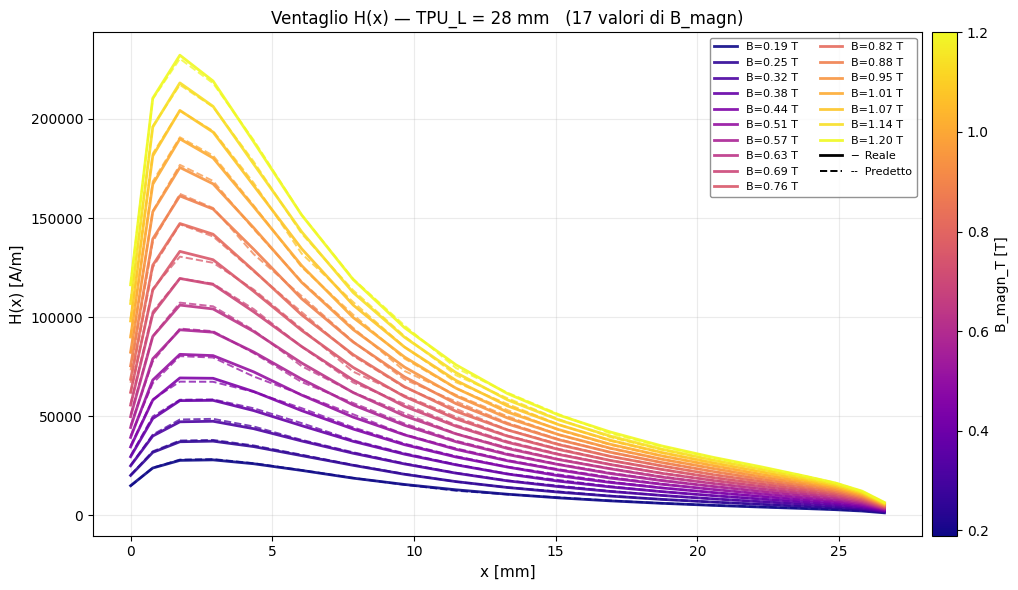

In [43]:
# ── PARAMETRI ────────────────────────────────────────────────────
TPU_IDX  = 8     # indice del TPU_L da plottare (0=20mm, 20=40mm)
SHOW_LOG = False  # True = asse y in scala logaritmica
# ─────────────────────────────────────────────────────────────────

tpu = tpu_vals[TPU_IDX]

df_tpu   = df_no_zero_t_1[df_no_zero_t_1['TPU_L_mm'] == tpu]
b_in_tpu = sorted(df_tpu['B_magn_T'].unique())

print(f"TPU_L = {tpu} mm  →  {len(b_in_tpu)} curve disponibili")
print(f"B_magn disponibili: {b_in_tpu}")

# Colormap sul range di B disponibile per questo TPU
cmap_fan = plt.cm.plasma
norm_fan = plt.Normalize(vmin=min(b_in_tpu), vmax=max(b_in_tpu))

fig, ax = plt.subplots(figsize=(11, 6))

for b in b_in_tpu:
    color  = cmap_fan(norm_fan(b))

    blocco = (df_tpu[df_tpu['B_magn_T'] == b]
              .sort_values('x_coord_m')
              .reset_index(drop=True))

    x_mm   = blocco['x_coord_m'].values * 1000   # metri → mm
    H_true = blocco['H_val_Am'].values
    B_val  = blocco['B_val_T'].values

    # Costruisci input con le stesse colonne usate nel training
    X_inp = np.column_stack([
        np.full(len(blocco), tpu),       # TPU_L_mm
        blocco['x_coord_m'].values,       # x_coord_m
        B_val,                            # B_val_T
    ])
    X_inp_s = scaler_X.transform(X_inp)

    model.eval()
    with torch.no_grad():
        H_pred_s = model(torch.FloatTensor(X_inp_s)).numpy().ravel()
    H_pred = scaler_y.inverse_transform(H_pred_s.reshape(-1, 1)).ravel()

    # Curva reale — continua, più spessa
    ax.plot(x_mm, H_true, '-',
            color=color, lw=2.0, alpha=0.9,
            label=f'B={b:.2f} T')

    # Curva predetta — tratteggiata, stesso colore
    ax.plot(x_mm, H_pred, '--',
            color=color, lw=1.4, alpha=0.75)

# Righe fantasma per spiegare la convenzione
ax.plot([], [], 'k-',  lw=2.0, label='─  Reale')
ax.plot([], [], 'k--', lw=1.4, label='╌  Predetto')

# Colorbar per B_magn
sm = plt.cm.ScalarMappable(cmap=cmap_fan, norm=norm_fan)
sm.set_array([])
plt.colorbar(sm, ax=ax, label='B_magn_T [T]', pad=0.01)

if SHOW_LOG:
    ax.set_yscale('log')

ax.set_title(f'Ventaglio H(x) — TPU_L = {tpu:.0f} mm   '
             f'({len(b_in_tpu)} valori di B_magn)',
             fontsize=12)
ax.set_xlabel('x [mm]', fontsize=11)
ax.set_ylabel('H(x) [A/m]', fontsize=11)
ax.legend(fontsize=8, loc='upper right', ncol=2,
          framealpha=0.85, edgecolor='grey')
ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.savefig(f'ventaglio_TPU{int(tpu)}mm.png', dpi=150, bbox_inches='tight')
plt.show()

In [44]:
# ── RMSE per ogni curva ad un TPU_L specifico ───────────────────────────────────────────
print(f"\nValutazione dettagliata per TPU_L = {tpu:.0f} mm")
print(f"\n{'B_magn [T]':>12} | {'RMSE [A/m]':>12} | {'MAE [A/m]':>12} | {'Max Err Rel':>12}")
print("-" * 55)

rmse_list = []
for b in b_in_tpu:
    blocco = (df_tpu[df_tpu['B_magn_T'] == b]
              .sort_values('x_coord_m')
              .reset_index(drop=True))

    H_true = blocco['H_val_Am'].values
    B_val  = blocco['B_val_T'].values

    X_inp = np.column_stack([
        np.full(len(blocco), tpu),
        blocco['x_coord_m'].values,
        B_val,
    ])
    X_inp_s = scaler_X.transform(X_inp)

    model.eval()
    with torch.no_grad():
        H_pred_s = model(torch.FloatTensor(X_inp_s)).numpy().ravel()
    H_pred = scaler_y.inverse_transform(H_pred_s.reshape(-1,1)).ravel()

    rmse    = np.sqrt(np.mean((H_pred - H_true) ** 2))
    mae     = np.mean(np.abs(H_pred - H_true))
    rel_max = (np.abs(H_pred - H_true) / (np.abs(H_true) + 1e-9)).max()

    rmse_list.append(rmse)
    print(f"{b:>12.3f} | {rmse:>12.1f} | {mae:>12.1f} | {rel_max:>11.2%}")

print("-" * 55)
print(f"{'RMSE medio':>12} | {np.mean(rmse_list):>12.1f}")


Valutazione dettagliata per TPU_L = 28 mm

  B_magn [T] |   RMSE [A/m] |    MAE [A/m] |  Max Err Rel
-------------------------------------------------------
       0.189 |        221.1 |        189.0 |      19.90%
       0.253 |        315.7 |        233.5 |      11.15%
       0.316 |        545.6 |        374.7 |       7.84%
       0.379 |        557.1 |        399.5 |       6.04%
       0.442 |        739.8 |        491.9 |       4.72%
       0.505 |        839.3 |        556.6 |       3.71%
       0.568 |        670.5 |        502.5 |       2.92%
       0.632 |        712.6 |        482.0 |       2.65%
       0.695 |        637.3 |        433.7 |       2.20%
       0.758 |        959.6 |        616.4 |       2.85%
       0.821 |        739.1 |        492.9 |       2.61%
       0.884 |       1035.1 |        694.6 |       3.01%
       0.947 |        766.3 |        534.7 |       2.62%
       1.011 |        703.1 |        500.7 |       1.96%
       1.074 |        895.4 |        600.7 |

In [45]:
# ── RMSE per ogni curva ad ogni TPU_L ────────────────────────────
print(f"\nValutazione dettagliata per tutti i TPU_L")
print(f"\n{'TPU_L':>8} | {'B_magn [T]':>10} | {'RMSE [A/m]':>12} | {'MAE [A/m]':>12} | {'ErrRel Max':>12} | {'ErrRel Med':>12}")
print("-" * 80)

rmse_all = []

for tpu in tpu_vals:
    df_tpu   = df_no_zero_t_1[df_no_zero_t_1['TPU_L_mm'] == tpu]
    b_in_tpu = sorted(df_tpu['B_magn_T'].unique())

    for b in b_in_tpu:
        blocco = (df_tpu[df_tpu['B_magn_T'] == b]
                  .sort_values('x_coord_m')
                  .reset_index(drop=True))

        H_true = blocco['H_val_Am'].values
        B_val  = blocco['B_val_T'].values
        x_mm   = blocco['x_coord_m'].values * 1000

        X_inp = np.column_stack([
            np.full(len(blocco), tpu),
            blocco['x_coord_m'].values,
            B_val,
        ])
        X_inp_s = scaler_X.transform(X_inp)
        # print(X_inp_s)

        model.eval()
        with torch.no_grad():
            H_pred_s = model(torch.FloatTensor(X_inp_s)).numpy().ravel()
        H_pred = scaler_y.inverse_transform(H_pred_s.reshape(-1,1)).ravel()

        err_abs  = np.abs(H_pred - H_true)
        err_rel  = err_abs / (np.abs(H_true) + 1e-9)

        rmse     = np.sqrt(np.mean((H_pred - H_true) ** 2))
        mae      = np.mean(err_abs)
        rel_max  = err_rel.max()
        rel_mean = err_rel.mean()

        rmse_all.append({
            'TPU_L_mm'   : tpu,
            'B_magn_T'   : b,
            'RMSE'       : rmse,
            'MAE'        : mae,
            'RelErr_max' : rel_max,
            'RelErr_mean': rel_mean,
            'x_mm'       : x_mm,
            'H_true'     : H_true,
            'H_pred'     : H_pred,
            'err_abs'    : err_abs,
        })

        
        print(f"{tpu:>7.0f}mm | {b:>10.3f} | {rmse:>12.1f} | " f"{mae:>12.1f} | {rel_max*100:>11.2f}% | {rel_mean*100:>11.2f}%")




Valutazione dettagliata per tutti i TPU_L

   TPU_L | B_magn [T] |   RMSE [A/m] |    MAE [A/m] |   ErrRel Max |   ErrRel Med
--------------------------------------------------------------------------------
     20mm |      0.253 |        790.6 |        691.6 |       13.40% |        4.32%
     20mm |      0.316 |        634.1 |        556.0 |        9.01% |        3.10%
     20mm |      0.379 |        542.9 |        470.4 |        7.07% |        2.28%
     20mm |      0.442 |        769.8 |        655.1 |        6.43% |        2.12%
     20mm |      0.505 |        734.3 |        642.8 |        6.34% |        1.79%
     20mm |      0.568 |        672.3 |        545.0 |        5.84% |        1.40%
     20mm |      0.632 |        816.6 |        653.7 |        5.95% |        1.37%
     20mm |      0.695 |        813.2 |        629.6 |        6.04% |        1.28%
     20mm |      0.758 |        892.0 |        642.2 |        4.42% |        1.17%
     20mm |      0.821 |       1020.3 |       

In [46]:
# ── Riepilogo ────────────────────────────────────────────────────
df_rmse_all = pd.DataFrame([{k: v for k, v in r.items()
                              if k not in ('x_mm','H_true','H_pred','err_abs')}
                             for r in rmse_all])

df_rmse_all['RelErr_max %']  = (df_rmse_all['RelErr_max']  * 100).round(2)
df_rmse_all['RelErr_mean %'] = (df_rmse_all['RelErr_mean'] * 100).round(2)

print(f"\n{'='*80}")
print(f"Totale curve valutate: {len(rmse_all)}")
print(f"RMSE medio globale:    {df_rmse_all['RMSE'].mean():.1f} A/m")
print(f"RMSE mediano:          {df_rmse_all['RMSE'].median():.1f} A/m")

print(f"\n── Top 5 peggiori per RMSE ──")
print(df_rmse_all.nlargest(5, 'RMSE')
      [['TPU_L_mm','B_magn_T','RMSE','MAE','RelErr_max %','RelErr_mean %']]
      .to_string(index=False))

print(f"\n── Top 20 peggiori per errore relativo massimo ──")
print(df_rmse_all.nlargest(20, 'RelErr_max')
      [['TPU_L_mm','B_magn_T','RMSE','MAE','RelErr_max %','RelErr_mean %']]
      .to_string(index=False))

print(f"\n - Numero di curve con errore relativo massimo > 20%: {df_rmse_all[df_rmse_all['RelErr_max %'] > 20].shape[0]}")
print(f"\n - Numero di curve con errore relativo massimo > 10%: {df_rmse_all[df_rmse_all['RelErr_max %'] > 10].shape[0]}")


Totale curve valutate: 356
RMSE medio globale:    576.1 A/m
RMSE mediano:          571.8 A/m

── Top 5 peggiori per RMSE ──
 TPU_L_mm  B_magn_T        RMSE         MAE  RelErr_max %  RelErr_mean %
       20  1.200000 2146.208433 1331.091985          5.47           1.38
       21  1.200000 1760.740430 1139.083817          2.84           1.08
       22  1.200000 1467.981616 1040.458441          2.51           1.03
       20  0.884211 1146.657452  942.537270          4.25           1.39
       23  1.200000 1131.655035  805.225046          1.55           0.84

── Top 20 peggiori per errore relativo massimo ──
 TPU_L_mm  B_magn_T        RMSE        MAE  RelErr_max %  RelErr_mean %
       37  0.189474  325.699926 237.252036         39.92           5.70
       36  0.189474  328.923626 232.642179         39.75           5.49
       35  0.189474  324.158561 231.844778         37.60           5.22
       34  0.189474  318.069795 229.348262         35.38           4.93
       33  0.189474  299.3